In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torchvision.models import efficientnet_b3,EfficientNet_B3_Weights

In [2]:
device = torch.device('cuda'if torch.cuda.is_available() else 'cpu')
device

device(type='cpu')

In [3]:
num_classes = 15
model = models.mobilenet_v2(pretrained=True)

c:\Users\Ariopc.ir\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Ariopc.ir\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [4]:
model.classifier[1] = nn.Linear(model.last_channel,num_classes)
model = model.to(device)

In [5]:
from torch.utils.data import DataLoader


BALL_TRAIN_DIR = "./data/ball/train"
BALL_TEST_DIR = "./data/ball/test"

IMG_SIZE = 224
BATCH_SIZE = 32

In [6]:
# ----------------------------
# Transforms
# ----------------------------
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5) ,
    transforms.RandomRotation(degrees=15) ,
    transforms.RandomResizedCrop(IMG_SIZE ,scale=(0.8 , 1.0)) ,
    transforms.ColorJitter(brightness=0.2 , contrast=0.2 , saturation=0.2 , hue=0.1) ,
    transforms.ToTensor(),  # scales images to [0, 1]
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [7]:
# ----------------------------
# Datasets
# ----------------------------
train_dataset = datasets.ImageFolder(
    root=BALL_TRAIN_DIR,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=BALL_TEST_DIR,
    transform=transform
)

In [8]:
# ----------------------------
# DataLoaders
# ----------------------------
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
model.train()
NUM_EPOCH = 10

for epoch in range(NUM_EPOCH):

    running_loss = 0.0
    correct = 0
    total = 0

    for inputs , labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        acc = (correct / total)*100

    print(
    f'---- Epoch {epoch} / {NUM_EPOCH} ----' ,
    f'correct : {correct } / total : {total}  , acc : {acc : .2f} '
    )

    print(f'epoch {epoch+1} completed')

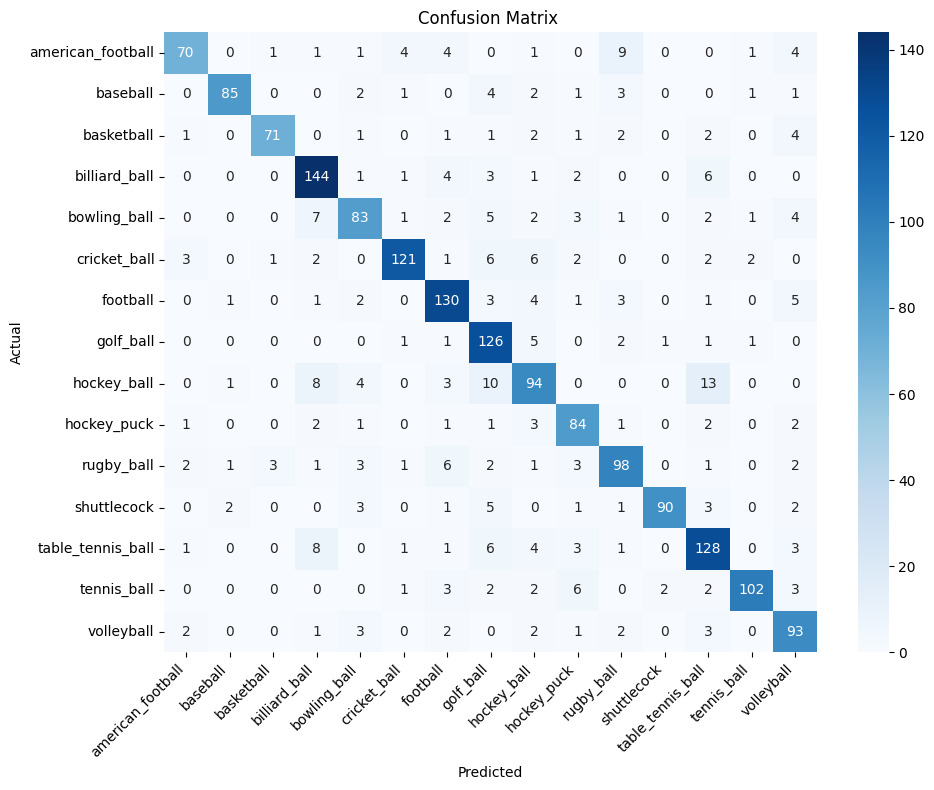

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns 
import matplotlib.pyplot as plt

#predicition
model.eval()
all_labels = []
all_preds = []
with torch.no_grad():
    for images,labels in test_loader:
        images,labels = images.to(device),labels.to(device)
        outputs = model(images)
        _,predicted = torch.max(outputs,1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())
cm = confusion_matrix(all_labels,all_preds)
plt.figure(figsize=(10,8))
sns.heatmap(cm,annot=True,fmt = 'd',cmap = 'Blues',
            xticklabels=train_dataset.classes,
            yticklabels=train_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix ')
plt.xticks(rotation = 45,ha = 'right')
plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import torch.nn.functional as F

In [ ]:
def predict_ball_type (image_path , model , class_names) :
    img = Image.open(image_path).convert('RGB')
    img_tensor = transform(img).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(img_tensor)
        probablities = F.softmax(outputs,dim=1)
        confidence , predicted = torch.max(probablities ,1)

    return class_names[predicted.item()] ,confidence.item()

In [ ]:
img_path = './data/project/bowling_ball/images (4).JPG'
class_names = train_dataset.classes
print("Classes:", class_names)

label , conf = predict_ball_type( image_path=img_path , model=model , class_names=class_names )
print (f'prediction : {label} , acc :{ conf : .2f}')

Classes: ['american_football', 'baseball', 'basketball', 'billiard_ball', 'bowling_ball', 'cricket_ball', 'football', 'golf_ball', 'hockey_ball', 'hockey_puck', 'rugby_ball', 'shuttlecock', 'table_tennis_ball', 'tennis_ball', 'volleyball']
prediction : bowling_ball , acc : 1.00
